# M2.3a–M2.3b — Thống kê suy luận sensor đầu/cuối vòng đời trên FD001 train

Notebook này tạo artifact chính thức cho mốc M2.3a và hình/diễn giải của M2.3b. Phân tích chỉ đọc data/raw/train_FD001.txt, tạo mean của 30 cycles đầu và 30 cycles cuối theo từng engine, rồi tính effect size, bootstrap confidence interval, Wilcoxon permutation, Benjamini–Hochberg FDR và hình trực quan theo cấu hình M2.0 đã chốt.


## Phạm vi

- Đơn vị phân tích là train engine; mỗi engine đóng góp một difference late_mean - early_mean cho từng sensor.
- Notebook không đọc test_FD001.txt hoặc RUL_FD001.txt.
- Output gồm hai CSV, JSON metadata/validation và hai hình PNG được tạo trực tiếp từ artifact đã kiểm tra.
- Hình dùng panel riêng cho từng sensor vì sensor có thang đo khác nhau; không dùng hình để xếp hạng hoặc chọn feature.


In [1]:
from pathlib import Path
import sys

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'data' / 'raw' / 'train_FD001.txt').exists():
            return candidate
    raise RuntimeError('Không tìm thấy thư mục gốc repository.')

PROJECT_ROOT = find_project_root(Path.cwd()).resolve()
src_path = PROJECT_ROOT / 'src'
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))
PROJECT_ROOT

WindowsPath('D:/IUH/BigData/Final_Project')

In [2]:
import pandas as pd

from cmapss.statistics import SensorInferenceConfig
from cmapss.statistics_artifacts import write_sensor_statistics_artifacts

## Cấu hình M2.0

Các tham số dưới đây được lấy từ `SensorInferenceConfig` và không phụ thuộc vào default ngầm của SciPy/NumPy.

In [3]:
config = SensorInferenceConfig()
config

SensorInferenceConfig(bootstrap_resamples=10000, bootstrap_confidence_level=0.95, bootstrap_method='percentile', bootstrap_quantile_method='linear', wilcoxon_alternative='two-sided', wilcoxon_zero_method='wilcox', wilcoxon_correction=False, wilcoxon_method='permutation', wilcoxon_permutation_resamples=100000, fdr_method='bh', fdr_q=0.05, fdr_family_size=21, seed=42)

## Tạo artifact

Hàm bên dưới đọc raw train, kiểm tra FD001 profile, tạo bảng cặp, tính bảng suy luận, ghi CSV bằng precision bảo toàn float64, đọc lại CSV và chạy validator round-trip trước khi ghi run_info.json và validation.json.


In [4]:
result = write_sensor_statistics_artifacts(
    project_root=PROJECT_ROOT,
    raw_dir='data/raw',
    output_dir='outputs/statistics',
    config=config,
)
result.validation

{'status': 'passed',
 'scope': 'M2.3a artifact validation for train-only sensor inference',
 'test_data_used': False,
 'test_labels_used': False,
 'raw_sha256_unchanged': True,
 'config_matches_m20': True,
 'engine_sensor_pairs': {'rows': 2100,
  'expected_rows': 2100,
  'roundtrip': 'passed',
  'pairs_per_sensor': 100,
  'sensors_per_engine': 21,
  'window_cycles': 30},
 'sensor_inference': {'rows': 21,
  'expected_rows': 21,
  'roundtrip': 'passed',
  'test_status_counts': {'all_zero_difference': 6, 'ok': 15},
  'bootstrap_status_counts': {'degenerate': 6, 'ok': 15},
  'fdr_reject_true': 15,
  'raw_p_values_defined': 15},
 'checks': ['read_observations(train) and validate_fd001_profile passed',
  'validate_engine_sensor_pairs passed before and after CSV round-trip',
  'validate_sensor_inference passed before and after CSV round-trip',
  'raw train SHA-256 unchanged',
  'bootstrap_resamples=10000',
  'wilcoxon_permutation_resamples=100000']}

## Kiểm tra nhanh bảng xuất ra

Bảng sensor_inference.csv giữ đủ 21 sensors. Notebook hiển thị các cột chính để kiểm tra hình dạng và trạng thái, chưa dùng bảng này để chọn feature.


In [5]:
display_columns = [
    'sensor', 'n_pairs', 'n_positive', 'n_negative', 'n_zero',
    'mean_difference', 'median_difference', 'ci_lower', 'ci_upper',
    'raw_p_value', 'p_value_adjusted', 'fdr_reject', 'test_status',
]
result.inference.loc[:, display_columns]

,sensor,n_pairs,n_positive,n_negative,n_zero,mean_difference,median_difference,ci_lower,ci_upper,raw_p_value,p_value_adjusted,fdr_reject,test_status
0,sensor_1,100,0,0,100,0.000000,0.000000,0.000000,0.000000,NaN,NaN,<NA>,all_zero_difference
1,sensor_2,100,100,0,0,0.999310,0.969000,0.959059,1.040183,0.00002,0.000028,True,ok
2,sensor_3,100,100,0,0,11.908667,11.681667,11.443951,12.377164,0.00002,0.000028,True,ok
3,sensor_4,100,100,0,0,20.128097,20.434333,19.402735,20.865606,0.00002,0.000028,True,ok
4,sensor_5,100,0,0,100,0.000000,0.000000,0.000000,0.000000,NaN,NaN,<NA>,all_zero_difference
5,sensor_6,100,47,0,53,0.000447,0.000000,0.000320,0.000580,0.00002,0.000028,True,ok
6,sensor_7,100,0,100,0,-1.913527,-1.886000,-1.999307,-1.829684,0.00002,0.000028,True,ok
7,sensor_8,100,100,0,0,0.130297,0.133333,0.119533,0.141294,0.00002,0.000028,True,ok
8,sensor_9,100,71,29,0,31.531620,17.630333,24.236336,39.319072,0.00002,0.000028,True,ok
9,sensor_10,100,0,0,100,0.000000,0.000000,0.000000,0.000000,NaN,NaN,<NA>,all_zero_difference


In [6]:
{
    'pair_rows': len(result.pairs),
    'inference_rows': len(result.inference),
    'output_dir': result.output_dir.as_posix(),
    'tables': result.run_info['tables'],
}

{'pair_rows': 2100,
 'inference_rows': 21,
 'output_dir': 'D:/IUH/BigData/Final_Project/outputs/statistics',
 'tables': ['outputs/statistics/tables/engine_sensor_pairs.csv',
  'outputs/statistics/tables/sensor_inference.csv']}

## M2.3b — Hình phân phối và effect size

Các hình dưới đây đọc bảng cặp và bảng suy luận vừa tạo. Mỗi panel tương ứng với một sensor, giữ nguyên thứ tự sensor_1 đến sensor_21. Đường dọc tại 0 là mốc không thay đổi; đường màu cam trong hình phân phối là mean paired difference. Hình effect size dùng khoảng tin cậy bootstrap 95% đã ghi trong CSV. Vì các sensor có thang đo khác nhau, mỗi panel có trục x riêng và không được dùng để so sánh trực tiếp độ lớn giữa sensors.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pairs_for_plot = result.pairs.copy()
inference_for_plot = result.inference.copy()
figure_dir = PROJECT_ROOT / 'outputs' / 'statistics' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)

sensor_order = inference_for_plot['sensor'].tolist()


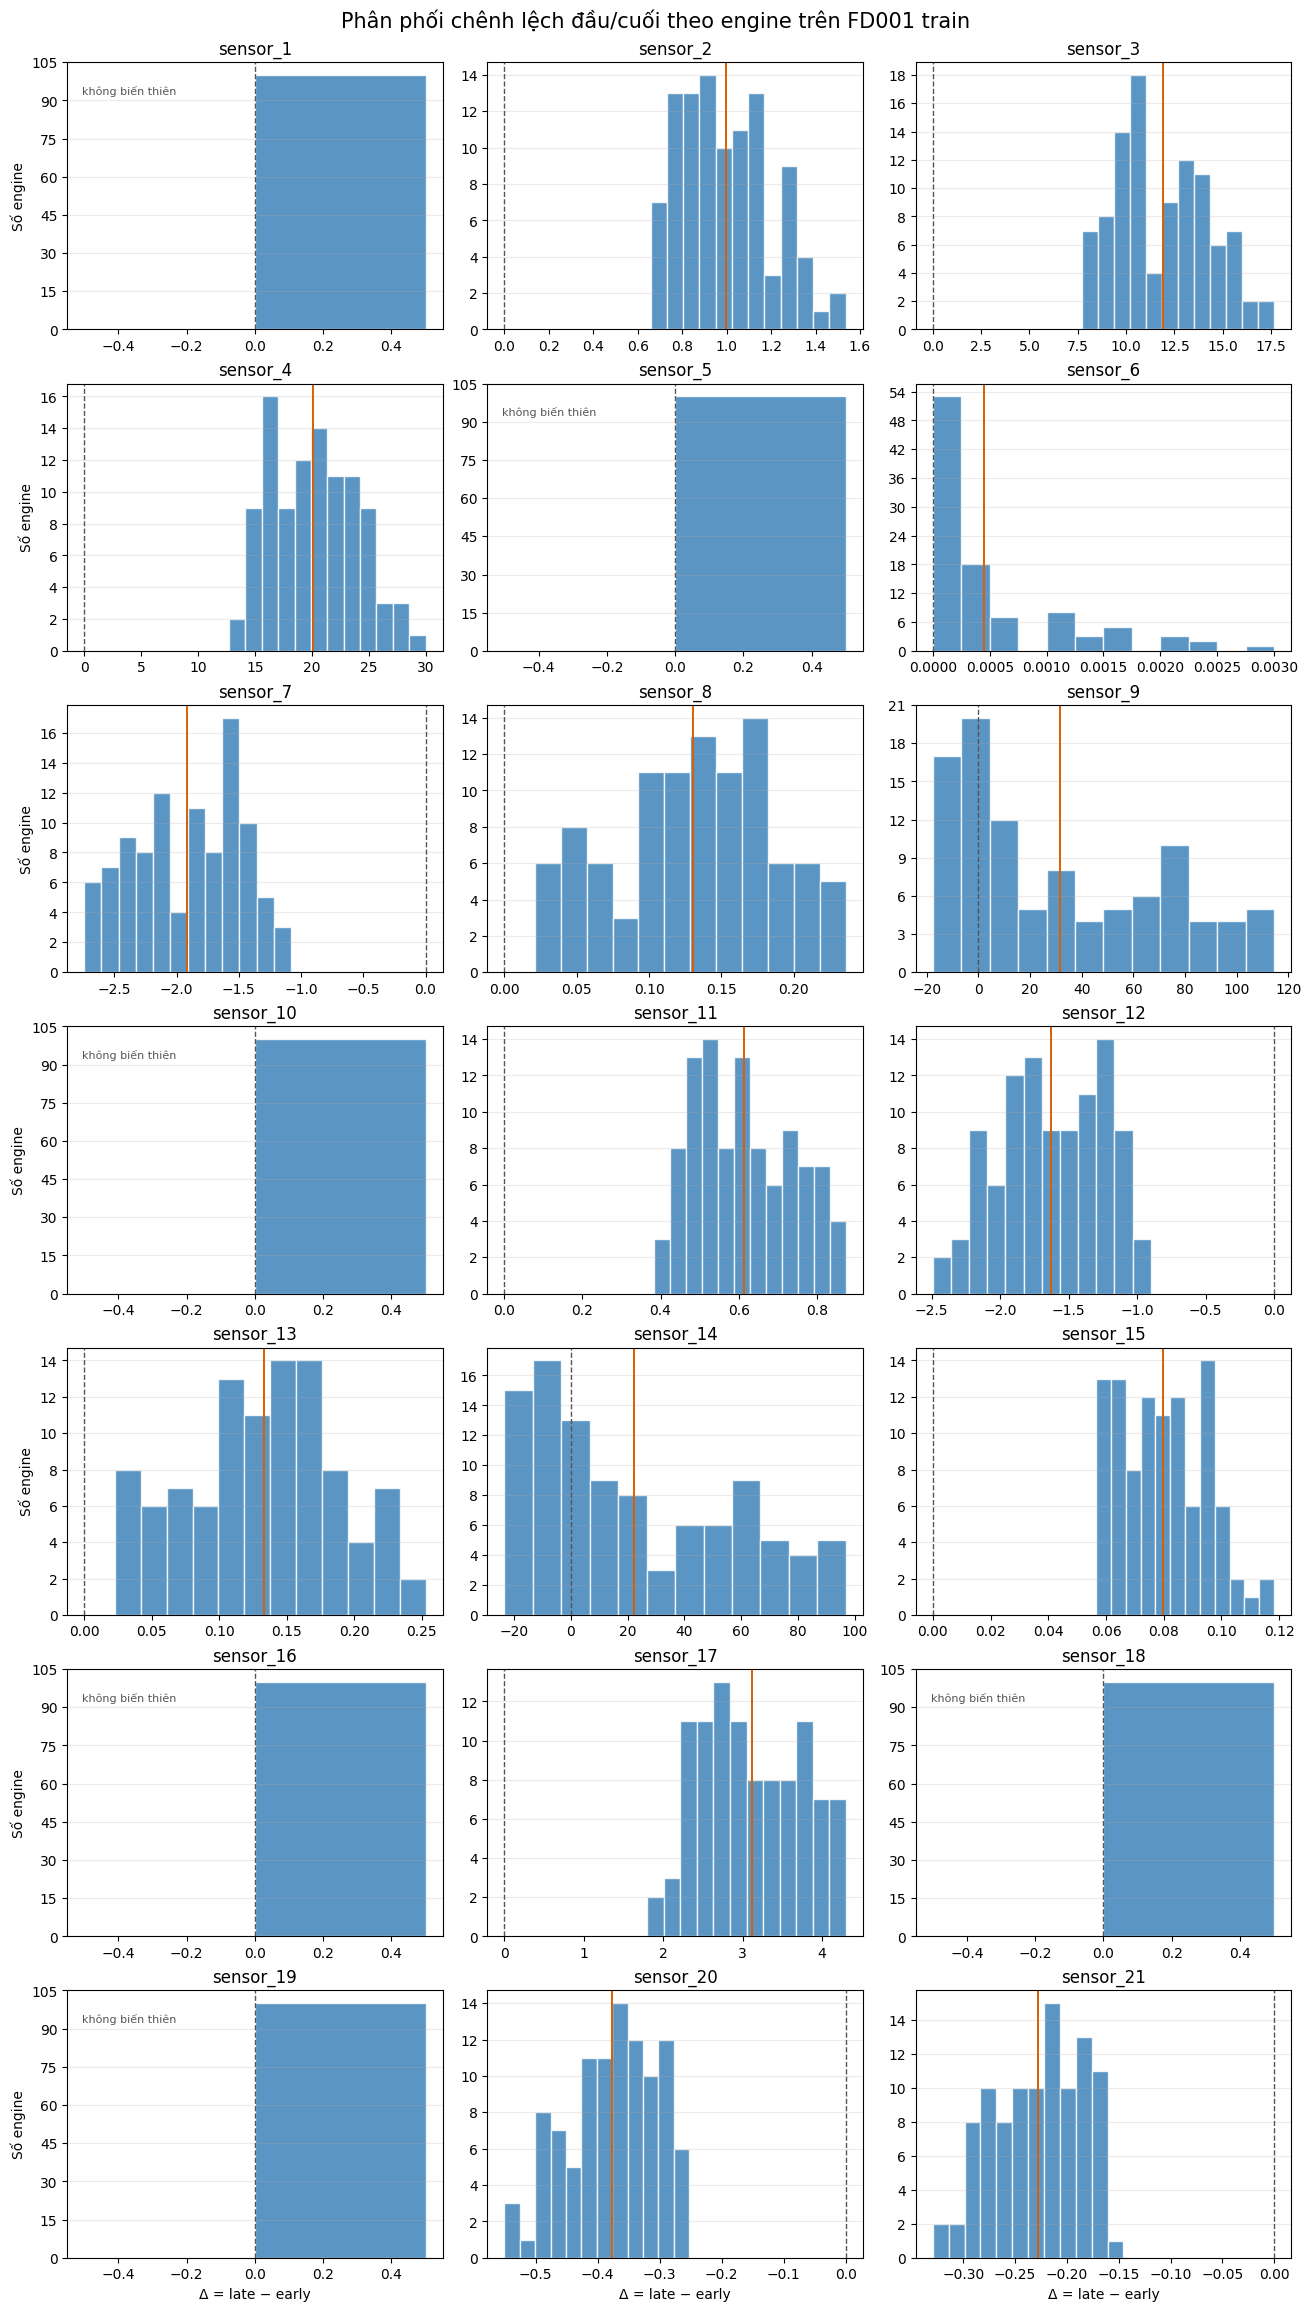

WindowsPath('D:/IUH/BigData/Final_Project/outputs/statistics/figures/difference_distributions.png')

In [8]:
# Phân phối difference theo engine, với một panel cho mỗi sensor.
fig, axes = plt.subplots(
    nrows=7,
    ncols=3,
    figsize=(13, 23),
    constrained_layout=True,
)
axes = axes.ravel()

for index, sensor in enumerate(sensor_order):
    ax = axes[index]
    values = pairs_for_plot.loc[
        pairs_for_plot['sensor'].eq(sensor), 'difference'
    ].astype(float).to_numpy()
    row = inference_for_plot.loc[
        inference_for_plot['sensor'].eq(sensor)
    ].iloc[0]
    value_range = float(values.max() - values.min())

    if value_range == 0:
        half_width = max(abs(float(values[0])) * 0.05, 0.5)
        bins = np.linspace(float(values[0]) - half_width, float(values[0]) + half_width, 3)
    else:
        bins = np.linspace(float(values.min()), float(values.max()), 13)

    ax.hist(values, bins=bins, color='#377eb8', alpha=0.82, edgecolor='white')
    ax.axvline(0, color='#555555', linewidth=1.0, linestyle='--')
    if value_range == 0:
        ax.text(
            0.04,
            0.88,
            'không biến thiên',
            transform=ax.transAxes,
            fontsize=8,
            color='#555555',
        )
    else:
        ax.axvline(
            float(row['mean_difference']),
            color='#d95f02',
            linewidth=1.4,
            label='mean',
        )

    ax.set_title(sensor)
    ax.grid(axis='y', alpha=0.25)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    if index // 3 == 6:
        ax.set_xlabel('Δ = late − early')
    if index % 3 == 0:
        ax.set_ylabel('Số engine')

fig.suptitle(
    'Phân phối chênh lệch đầu/cuối theo engine trên FD001 train',
    fontsize=15,
)
distribution_path = figure_dir / 'difference_distributions.png'
fig.savefig(distribution_path, dpi=180, facecolor='white')
plt.show()
plt.close(fig)

distribution_path


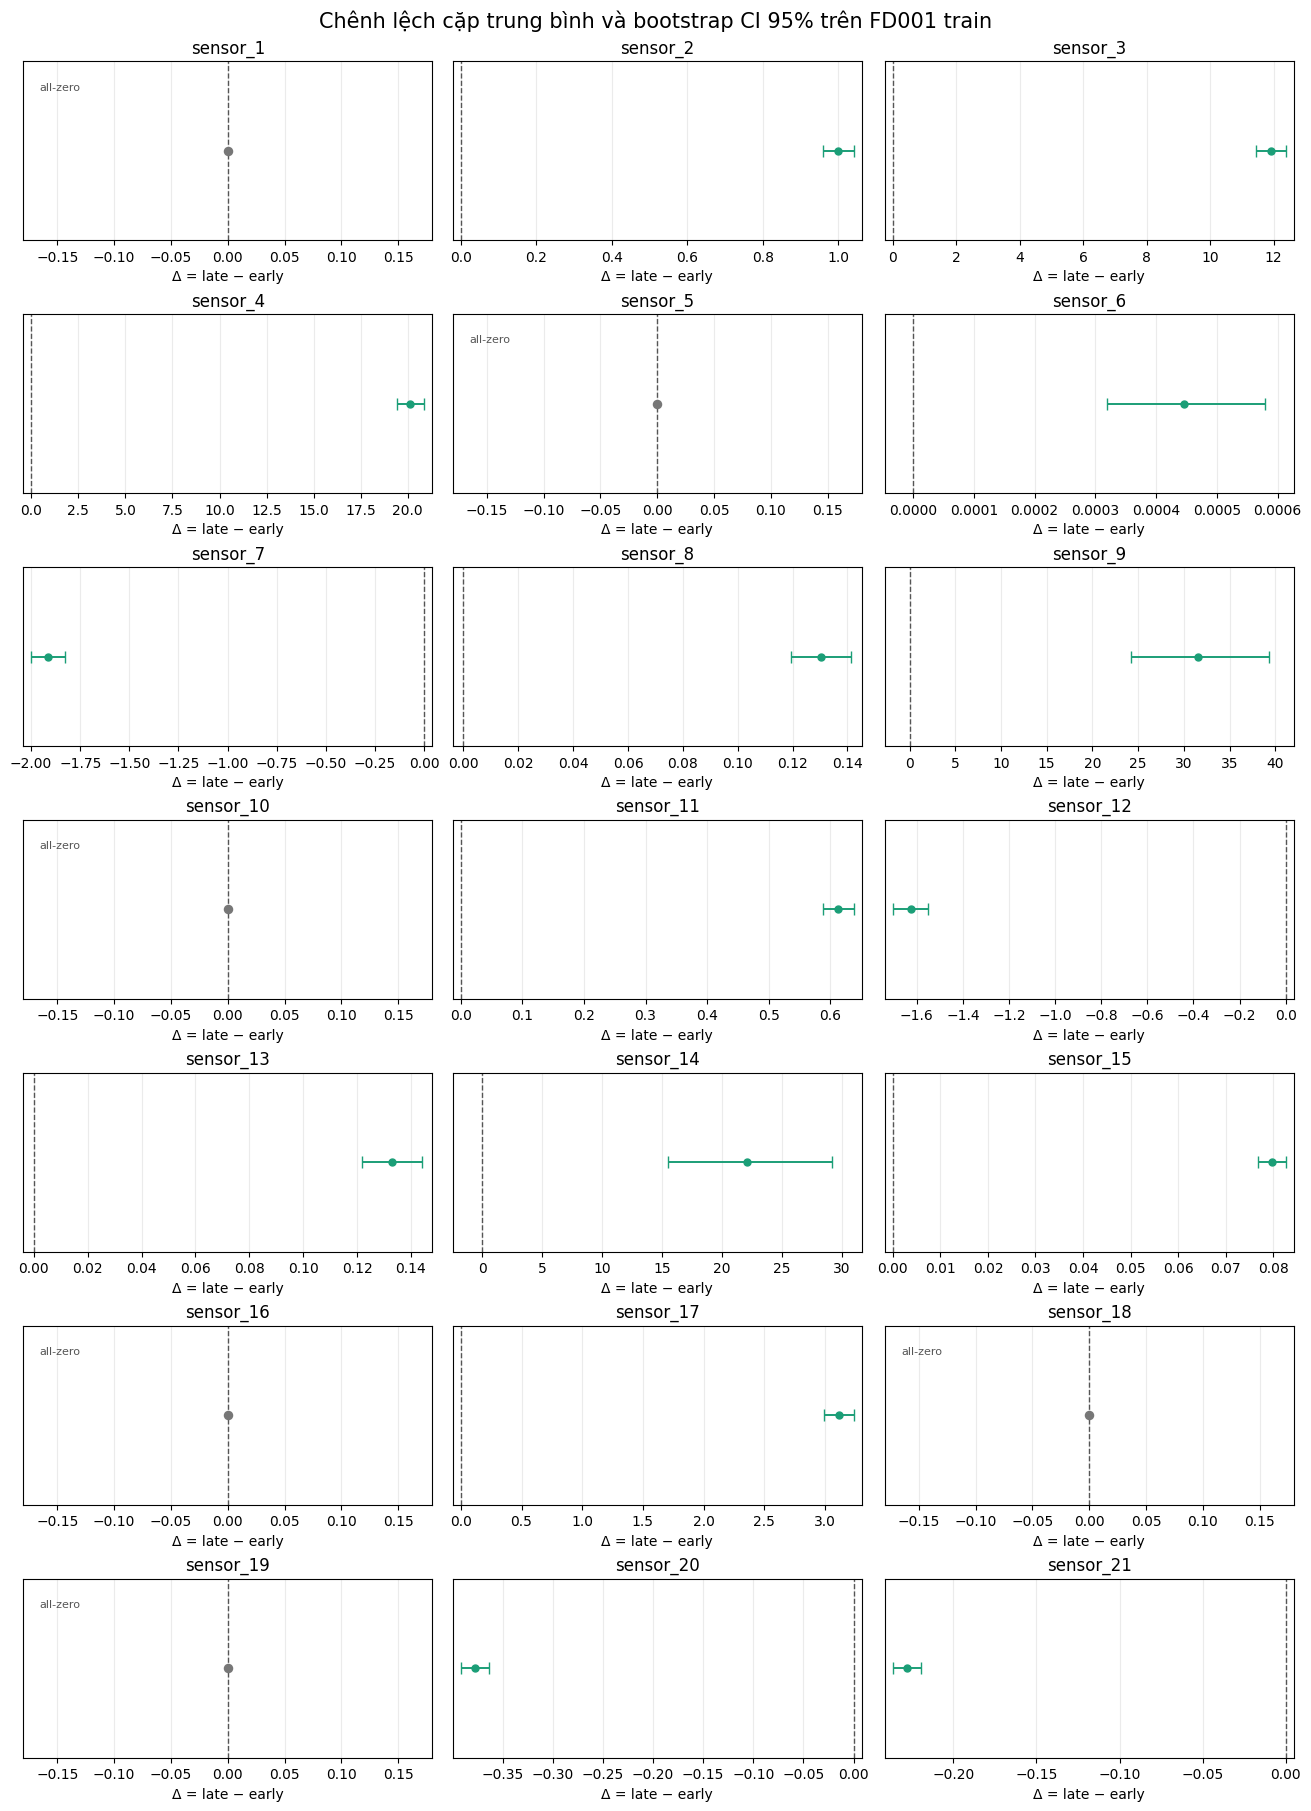

WindowsPath('D:/IUH/BigData/Final_Project/outputs/statistics/figures/effect_size_ci.png')

In [9]:
# Effect size (mean difference) và bootstrap CI 95%, với một panel cho mỗi sensor.
fig, axes = plt.subplots(
    nrows=7,
    ncols=3,
    figsize=(13, 18),
    constrained_layout=True,
)
axes = axes.ravel()

for index, sensor in enumerate(sensor_order):
    ax = axes[index]
    row = inference_for_plot.loc[
        inference_for_plot['sensor'].eq(sensor)
    ].iloc[0]
    mean_difference = float(row['mean_difference'])
    ci_lower = float(row['ci_lower'])
    ci_upper = float(row['ci_upper'])
    is_all_zero = row['test_status'] == 'all_zero_difference'

    if is_all_zero:
        span = 1.0
        ax.scatter([0], [0], color='#777777', s=34, zorder=3)
        ax.text(
            0.04,
            0.84,
            'all-zero',
            transform=ax.transAxes,
            fontsize=8,
            color='#555555',
        )
    else:
        span = max(ci_upper - ci_lower, abs(mean_difference) * 0.12, 1e-9)
        ax.errorbar(
            [mean_difference],
            [0],
            xerr=[[mean_difference - ci_lower], [ci_upper - mean_difference]],
            fmt='o',
            color='#1b9e77',
            ecolor='#1b9e77',
            capsize=4,
            markersize=5,
            linewidth=1.4,
            zorder=3,
        )

    left = min(0.0, ci_lower) - 0.18 * span
    right = max(0.0, ci_upper) + 0.18 * span
    if left == right:
        left, right = -1.0, 1.0
    ax.set_xlim(left, right)
    ax.axvline(0, color='#555555', linewidth=1.0, linestyle='--')
    ax.set_ylim(-0.7, 0.7)
    ax.set_yticks([])
    ax.set_title(sensor)
    ax.set_xlabel('Δ = late − early')
    ax.grid(axis='x', alpha=0.25)

fig.suptitle(
    'Chênh lệch cặp trung bình và bootstrap CI 95% trên FD001 train',
    fontsize=15,
)
effect_path = figure_dir / 'effect_size_ci.png'
fig.savefig(effect_path, dpi=180, facecolor='white')
plt.show()
plt.close(fig)

effect_path


## Diễn giải M2.3b

Kết quả được đọc từ artifact vừa tạo, nên các nhận xét sau chỉ áp dụng cho thiết kế hồi cứu trên 100 train engines của FD001:

- 21 sensor đều xuất hiện trong bảng; 6 sensor có toàn bộ difference = 0 và được giữ với trạng thái all_zero_difference. Trạng thái này mô tả không có biến thiên quan sát được trong cặp 30 cycles đầu/cuối, không chứng minh sensor không có giá trị dự đoán.
- 15 sensor còn lại có đủ chênh lệch để kiểm định. Trong cấu hình Wilcoxon permutation và Benjamini–Hochberg FDR đã chốt trước khi chạy, các sensor kiểm định được đều bị bác bỏ giả thuyết không. Đây là kết luận về bằng chứng thống kê trong protocol này, không phải tiêu chí chọn feature.
- Độ lớn thay đổi phải đọc từ mean_difference và khoảng tin cậy theo đơn vị gốc của từng sensor. Ví dụ, sensor_4 tăng khoảng 20,13 còn sensor_7 giảm khoảng 1,91; hai con số này không được so sánh như cùng một thang đo.
- sensor_6 có 47 chênh lệch dương và 53 chênh lệch bằng 0, với mean difference chỉ khoảng 0,00045. Đây là ví dụ cho việc p-value nhỏ không đồng nghĩa với thay đổi lớn về mặt đơn vị đo.
- sensor_9 có 71 chênh lệch dương và 29 chênh lệch âm. Phân phối này cho thấy mean difference có thể che khuất khác biệt giữa các engine, vì vậy hình phân phối cần được xem cùng effect size và CI.
- Các kết quả này chưa đo khả năng dự đoán RUL ngoài mẫu. Feature selection, preprocessing và model selection vẫn phải được thực hiện bên trong training folds ở mốc mô hình để tránh data leakage.
